# BIOMASS – Freeman Decomposition

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import os
import matplotlib.pyplot as plt
from biomass.polarimetry_utils import find_measurement_folders, find_tiff_files, reconstruct_slc, freeman_decompose


from biomass.polarimetry_utils import (
    find_measurement_folders,
    find_tiff_files,
    reconstruct_slc,
    freeman_decompose,
)

TDS = "kufrah"
OUTPUT_DIR = f"../results/{TDS}"

os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Get TIFF abs and phase data

In [2]:
folders = find_measurement_folders(TDS)
tiffs   = {os.path.basename(f): find_tiff_files(f) for f in folders}

for name, paths in tiffs.items():
    print(f"{name}\n  abs:   {os.path.basename(paths['abs'])}\n  phase: {os.path.basename(paths['phase'])}\n")

BIO_S1_SCS__1S_20260513T164734_20260513T164754_T_G01_M03_C07_T040_F138_02_DREA51
  abs:   bio_s1_scs__1s_20260513t164734_20260513t164754_t_g01_m03_c07_t040_f138_i_abs.tiff
  phase: bio_s1_scs__1s_20260513t164734_20260513t164754_t_g01_m03_c07_t040_f138_i_phase.tiff

BIO_S1_SCS__1S_20260513T164753_20260513T164813_T_G01_M03_C07_T040_F139_02_DREADQ
  abs:   bio_s1_scs__1s_20260513t164753_20260513t164813_t_g01_m03_c07_t040_f139_i_abs.tiff
  phase: bio_s1_scs__1s_20260513t164753_20260513t164813_t_g01_m03_c07_t040_f139_i_phase.tiff



## 2. Reconstruct SLC image

In [3]:
S_mats = {name: reconstruct_slc(p["abs"], p["phase"]) for name, p in tiffs.items()}

for name, S in S_mats.items():
    print(f"{name}: shape={S['hh'].shape}, dtype={S['hh'].dtype}")

BIO_S1_SCS__1S_20260513T164734_20260513T164754_T_G01_M03_C07_T040_F138_02_DREA51: shape=(20755, 1329), dtype=complex64
BIO_S1_SCS__1S_20260513T164753_20260513T164813_T_G01_M03_C07_T040_F139_02_DREADQ: shape=(20756, 1329), dtype=complex64


## 3. Process Freeman decomposition

In [4]:
freeman_results = {}

for name, S in S_mats.items():
    out_nc = os.path.join(OUTPUT_DIR, f"freeman_{name}.nc")
    freeman_results[name] = freeman_decompose(S, out_nc)
    print(f"✓ {out_nc}")

[########################################] | 100% Completed | 11.99 s
✓ ../results/kufrah/freeman_BIO_S1_SCS__1S_20260513T164734_20260513T164754_T_G01_M03_C07_T040_F138_02_DREA51.nc
[########################################] | 100% Completed | 11.57 s
✓ ../results/kufrah/freeman_BIO_S1_SCS__1S_20260513T164753_20260513T164813_T_G01_M03_C07_T040_F139_02_DREADQ.nc


## 4. Visualize the results

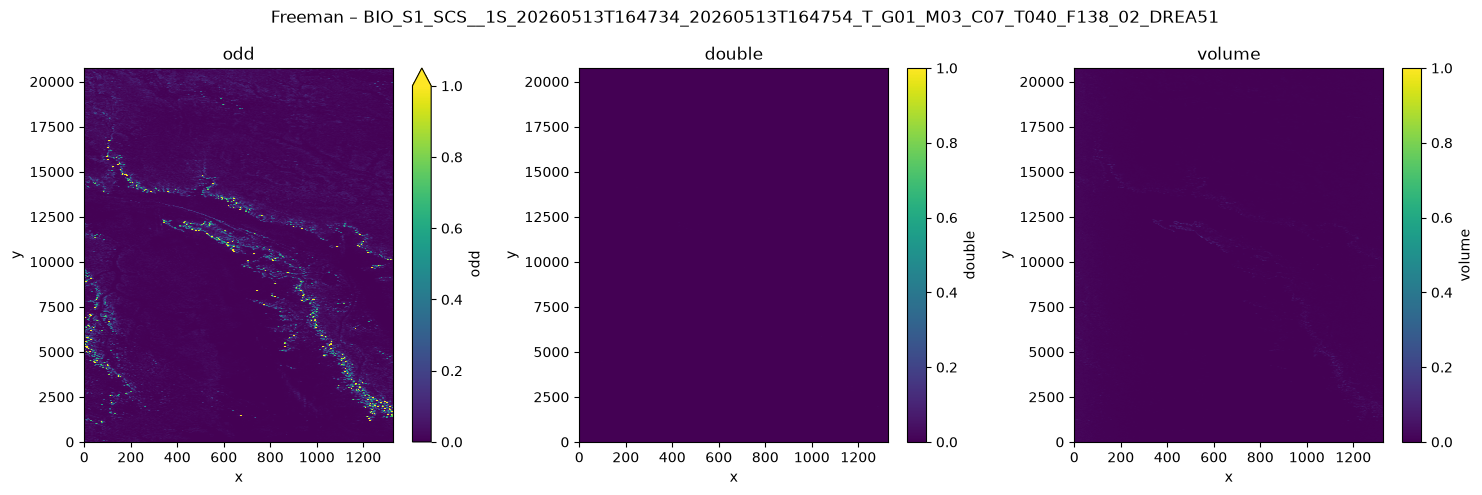

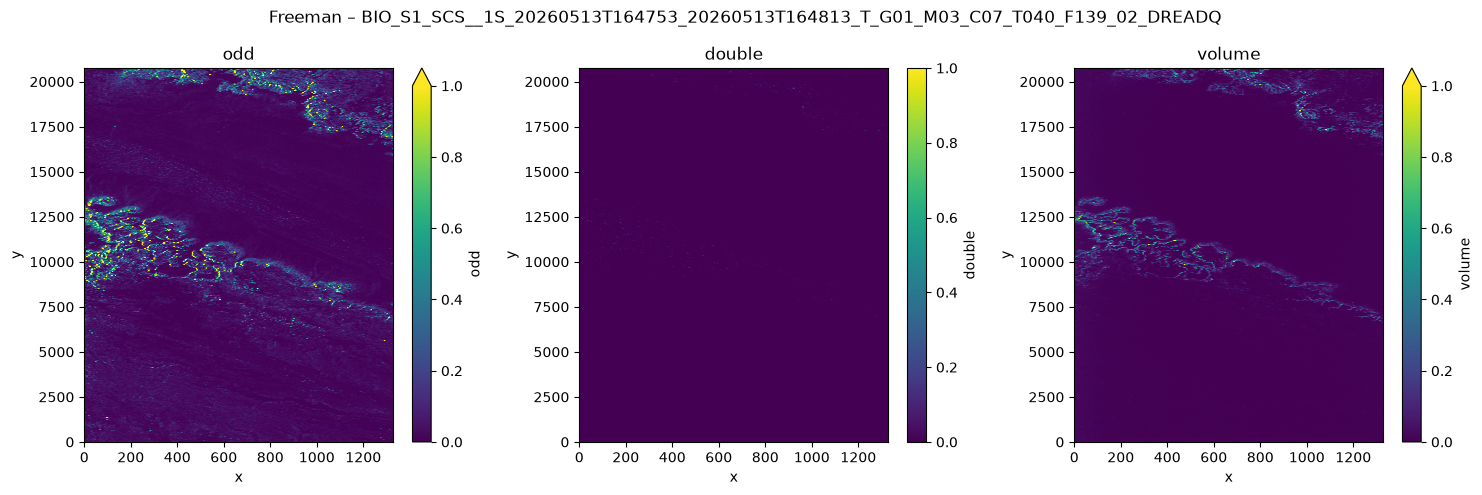

In [5]:
for name, ds in freeman_results.items():
    vars_ = [v for v in ds.data_vars if v not in ("y", "x")]
    fig, axes = plt.subplots(1, len(vars_), figsize=(5 * len(vars_), 5))
    if len(vars_) == 1:
        axes = [axes]
    for ax, var in zip(axes, vars_):
        ds[var].plot.imshow(ax=ax, vmin=0, vmax=1, cmap="viridis")
        ax.set_title(var)
    plt.suptitle(f"Freeman – {name}")
    plt.tight_layout()
    plt.show()